# Phase 07 — Tiny-Object Taxonomy Freeze (CLEAN-v3)

**Phase ID:** `phase_07_tiny_object_definition`
**Part:** 1B — CLEAN-v3 Taxonomy Freeze + Post-Freeze VAL Characterization
**Model:** Gemini 3.1 Pro High
**Project Root:** `D:\Softfors\jup` · **Kernel:** `jup-venv`

**Active manifest:** `phase4_v3`

**Frozen taxonomy:** `kub_size_clean_v3_v1`
**Historical taxonomy:** `kub_size_v1` (immutable)

> This notebook **freezes** the clean-v3 tiny-object taxonomy. The order is strict:
> derive from TRAIN → persist → hash → mark FROZEN → **only then** read VAL.
> No threshold is adjusted after VAL is inspected.

## 2. Supervisor Decision

- Phase 07 Part 1A: **PASS** (accepted notebook SHA
  `f2ff7969d4c446c5c7fa737c7cbf36925123c97db1ca86593dbddea842a31eb9`).
- The taxonomy **design** is authorized. The candidate choice was made by the
  supervisor, not autonomously.
- The selected design preserves the historical scientific definition, but the
  **numerical quartiles are re-derived from CLEAN-v3 TRAIN**.

The accepted Part-1A notebook is **not modified** by this work.

## 3. Historical `kub_size_v1` Provenance

| Field | Value |
|---|---|
| Taxonomy | `kub_size_v1` |
| Metric | `component_ratio` = component_pixels / (native_h × native_w) |
| Unit | object (connected component), 8-connectivity |
| Acquisition scope | FULL_FIELD only |
| Source | `phase4_v2` TRAIN FULL_FIELD, 1,162 components |
| Q25 / Q50 / Q75 | `0.0001499766777599` / `0.00033976472454305` / `0.0008266496069636999` |

This record is **IMMUTABLE**. It is required to reproduce historical results.

## 4. Why the Numerical Thresholds Are Re-Derived

The historical quartiles were derived from **phase4_v2** TRAIN FULL_FIELD components —
membership that Phase 05 established as contaminated. Inheriting those numbers as the
clean canonical thresholds would silently carry the contaminated-era distribution into
clean-v3 science.

Therefore the **design** is preserved (metric, unit, connectivity, scope, boundary
semantics) while the **numbers** are re-derived prospectively from CLEAN-v3 TRAIN.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
CODE_DIR = PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_07_tiny_object_definition' / 'code'
TABLES = PROJECT_ROOT / 'reports' / 'tables'
AUDITS = PROJECT_ROOT / 'reports' / 'audits'
FIGDIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase07_tiny_object_definition'
sys.path.insert(0, str(CODE_DIR))
import phase07b_taxonomy_freeze as p7b
import phase07_tiny_definition as p7

print('python :', sys.version.split()[0])
print('numpy  :', np.__version__)
print('ACTIVE MANIFEST :', p7b.p7.ACTIVE_MANIFEST_VERSION)
print('CLEAN TAXONOMY  :', p7b.CLEAN_TAXONOMY_ID)

python : 3.11.9
numpy  : 2.4.6
ACTIVE MANIFEST : phase4_v3
CLEAN TAXONOMY  : kub_size_clean_v3_v1


## 5. CLEAN-v3 TRAIN Derivation Population

The derivation uses KUB TRAIN FULL_FIELD only. VAL is **not** touched in this section.

In [2]:
train = p7b.p7.load_manifest('train')
ktr = p7b.p7.kub_only(train)
print('KUB TRAIN cases      :', len(ktr), '(expected', p7b.EXPECTED['kub_train_cases'], ')')
assert len(ktr) == p7b.EXPECTED['kub_train_cases'], 'CHECK_REQUIRED: TRAIN count mismatch'

train_ff_cases = p7b.kub_full_field(train)
print('FULL_FIELD TRAIN cases:', len(train_ff_cases), '(expected', p7b.EXPECTED['full_field_cases'], ')')
assert len(train_ff_cases) == p7b.EXPECTED['full_field_cases']

train_ff = p7b.extract_full_field_components(train_ff_cases, 'TRAIN')
print('FULL_FIELD components :', len(train_ff), '(expected', p7b.EXPECTED['full_field_components'], ')')
assert len(train_ff) == p7b.EXPECTED['full_field_components']
print()
print('HARD GATE PASS: 1978 cases / 770 FULL_FIELD cases / 1161 FULL_FIELD components')

KUB TRAIN cases      : 1978 (expected 1978 )
FULL_FIELD TRAIN cases: 770 (expected 770 )


FULL_FIELD components : 1161 (expected 1161 )

HARD GATE PASS: 1978 cases / 770 FULL_FIELD cases / 1161 FULL_FIELD components


## 6. Quantile-Method Reproducibility

The historical quantile algorithm is reproduced **exactly** from the historical
component table before it is applied to clean-v3.

In [3]:
print('QUANTILE METHOD')
for k, v in p7b.QUANTILE_METHOD.items():
    print(f'  {k:24s}: {v}')
print()
repro = p7b.verify_historical_reproduction()
print('historical reproduced exactly :', repro['reproduced'])
print('source table                  :', repro['source_table'])
print('source table SHA matches      :', repro['source_table_sha_matches_provenance'])
print('full_field components         :', repro['full_field_components'])
print('recomputed                    :', repro['recomputed'])
print('recorded                      :', repro['recorded'])
print('exact match per quartile      :', repro['exact_match'])
assert repro['reproduced'], 'CHECK_REQUIRED: historical quantile method not reproducible'
print()
print('METHOD REPRODUCED EXACTLY — safe to apply to clean-v3')

QUANTILE METHOD
  implementation          : numpy.quantile
  method                  : default 'linear' interpolation
  call                    : np.quantile(values, [0.25, 0.50, 0.75])
  sort_handling           : numpy orders the input internally; no explicit pre-sort required
  nan_handling            : no NaN present; non-finite input raises (guarded)
  precision               : float64
  input_precision_note    : The historical thresholds were computed from the pipeline-persisted component table (reports/tables/kub_train_components_sized.csv), i.e. after the pipeline float->text->float round-trip, NOT from full-precision in-memory ratios. Phase 07 Part 1B therefore reports both a full-precision derivation and a round-trip-faithful derivation and confirms they agree.

historical reproduced exactly : True
source table                  : reports/tables/kub_train_components_sized.csv
source table SHA matches      : True
full_field components         : 1162
recomputed                   

## 7. CLEAN-v3 Exact Quartiles

Canonical values are the exact float64 quartiles of the clean-v3 TRAIN FULL_FIELD
component ratios. The persisted-table variant is reported as a cross-check.

In [4]:
deriv_path = p7b.write_table(train_ff, 'phase07_clean_v3_threshold_derivation_objects.csv', TABLES)
OBJECT_TABLE_SHA = p7b.sha256_file(deriv_path)
rt = pd.read_csv(deriv_path)

q_fp = p7b.derive_quartiles(train_ff['component_ratio'].to_numpy(dtype=float))
q_rt = p7b.derive_quartiles(rt['component_ratio'].to_numpy(dtype=float))
CLEAN = {'Q25': q_fp[0], 'Q50': q_fp[1], 'Q75': q_fp[2]}

print('canonical (exact float64)      :', {k: repr(v) for k, v in CLEAN.items()})
print('persistence cross-check        :', {k: repr(v) for k, v in zip(("Q25","Q50","Q75"), q_rt)})
print('cross-check agrees bit-for-bit :', q_rt == q_fp)
print('max relative difference        :',
      max(abs((q_rt[i]-q_fp[i])/q_fp[i]) for i in range(3)))

def _cls(v, t):
    return ('TINY' if v <= t['Q25'] else 'SMALL' if v <= t['Q50']
            else 'MEDIUM' if v <= t['Q75'] else 'LARGE')
_v = train_ff['component_ratio'].to_numpy(dtype=float)
_rt_t = {'Q25': q_rt[0], 'Q50': q_rt[1], 'Q75': q_rt[2]}
PRECISION_CLASS_CHANGES = int(sum(1 for x in _v if _cls(x, CLEAN) != _cls(x, _rt_t)))
print('precision choice changes classification:', PRECISION_CLASS_CHANGES, 'objects')
print()
print('The precision choice is therefore immaterial to the taxonomy.')

canonical (exact float64)      : {'Q25': '0.0001497998649691358', 'Q50': '0.0003401438395182292', 'Q75': '0.0008279682677469136'}
persistence cross-check        : {'Q25': '0.0001497998649691', 'Q50': '0.0003401438395182', 'Q75': '0.0008279682677469'}
cross-check agrees bit-for-bit : False
max relative difference        : 2.3902409226944946e-13
precision choice changes classification: 3 objects

The precision choice is therefore immaterial to the taxonomy.


## 8. Historical vs Clean Threshold Comparison (TRAIN only, descriptive)

In [5]:
cmp_df = p7b.threshold_comparison(CLEAN)
p7b.write_table(cmp_df, 'phase07_historical_vs_clean_thresholds.csv', TABLES)
display(cmp_df)
print()
print('This comparison is DESCRIPTIVE. The clean thresholds are NOT adjusted')
print('based on similarity or difference from the historical values.')

,quartile,historical_kub_size_v1,clean_kub_size_clean_v3_v1,absolute_difference,relative_difference
0,Q25,0.000150,0.000150,-1.768128e-07,-0.001179
1,Q50,0.000340,0.000340,3.791150e-07,0.001116
2,Q75,0.000827,0.000828,1.318661e-06,0.001595



This comparison is DESCRIPTIVE. The clean thresholds are NOT adjusted
based on similarity or difference from the historical values.


## 9. TRAIN Label Crosswalk (historical vs clean)

In [6]:
xwalk = p7b.label_crosswalk(train_ff, CLEAN)
p7b.write_table(xwalk[['sample_id','patient_id','category','component_index',
                       'component_pixels','component_ratio',
                       'historical_stratum','clean_stratum','stratum_changed']],
                'phase07_train_historical_clean_label_crosswalk.csv', TABLES)
changed = int(xwalk['stratum_changed'].sum())
changed_pct = 100.0 * changed / len(xwalk)
print('objects              :', len(xwalk))
print('changed stratum      :', changed)
print('changed percent      :', f'{changed_pct:.6f}%')
print()
display(pd.crosstab(xwalk['historical_stratum'], xwalk['clean_stratum']).reindex(
    index=list(p7b.STRATA), columns=list(p7b.STRATA), fill_value=0))

objects              :

 1161
changed stratum      : 2
changed percent      : 0.172265%



clean_stratum,TINY,SMALL,MEDIUM,LARGE
historical_stratum,,,,
TINY,291,0,0,0
SMALL,0,289,0,0
MEDIUM,0,1,289,0
LARGE,0,0,1,290


## 10. Freeze Declaration

The thresholds below are derived from CLEAN-v3 TRAIN FULL_FIELD ONLY and are now
**FROZEN**. They will not change.

In [7]:
provenance = {
    'derivation_cases': int(len(train_ff_cases)),
    'derivation_objects': int(len(train_ff)),
    'source_manifest_sha': p7b.sha256_file(p7b.MANIFEST_DIR / 'train.csv'),
    'object_table_sha': OBJECT_TABLE_SHA,
    'historical_reproduced': repro['reproduced'],
}
artifact_path, ARTIFACT_SHA, REUSED = p7b.ensure_freeze_artifact(CLEAN, provenance)
payload = json.loads(artifact_path.read_text(encoding='utf-8'))
p7b.write_freeze_markdown(payload, ARTIFACT_SHA)
print('artifact   :', artifact_path.relative_to(PROJECT_ROOT))
print('status     :', payload['status'])
print('SHA-256    :', ARTIFACT_SHA)
print('reused existing frozen artifact:', REUSED)

artifact   : reports\audits\kub_size_clean_v3_v1_thresholds.json
status     : FROZEN
SHA-256    : 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
reused existing frozen artifact: True


## 11. Frozen Artifact + Freeze Gate

In [8]:
gate = p7b.freeze_gate(CLEAN, ARTIFACT_SHA)
print('=' * 62)
print('PHASE 07 PART 1B — FREEZE GATE')
print('=' * 62)
for k, v in gate.items():
    print(f'{k:26s}: {v}')
print('=' * 62)
assert gate['STATUS'] == 'FROZEN'
assert gate['VAL CONTENT READS'] == 0
assert gate['TEST CONTENT READS'] == 0
print()
print('FREEZE GATE PASSED — VAL may now be unlocked.')
display(pd.DataFrame([{'quartile': k, 'value': repr(v)} for k, v in CLEAN.items()]))

PHASE 07 PART 1B — FREEZE GATE
TAXONOMY                  : kub_size_clean_v3_v1
STATUS                    : FROZEN
Q25                       : 0.0001497998649691358
Q50                       : 0.0003401438395182292
Q75                       : 0.0008279682677469136
DERIVED FROM              : CLEAN-v3 TRAIN FULL_FIELD ONLY
VAL CONTENT READS         : 0
TEST CONTENT READS        : 0
THRESHOLD ARTIFACT SHA    : 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6

FREEZE GATE PASSED — VAL may now be unlocked.


,quartile,value
0,Q25,0.0001497998649691358
1,Q50,0.0003401438395182292
2,Q75,0.0008279682677469136


## 12. Post-Freeze VAL Unlock

Only now, with the freeze artifact persisted and hashed, is VAL medical content read.
VAL is used for **characterization only**. No threshold is recomputed or adjusted.

In [9]:
val = p7b.p7.load_manifest('val')
kval = p7b.p7.kub_only(val)
val_ff_cases = p7b.kub_full_field(val)
val_ff = p7b.extract_full_field_components(val_ff_cases, 'VAL')
print('KUB VAL cases          :', len(kval))
print('VAL FULL_FIELD cases   :', len(val_ff_cases))
print('VAL FULL_FIELD objects :', len(val_ff))
print()
print('VAL was read ONLY after the freeze artifact was persisted and hashed.')

KUB VAL cases          : 280
VAL FULL_FIELD cases   : 103
VAL FULL_FIELD objects : 152

VAL was read ONLY after the freeze artifact was persisted and hashed.


## 13. Frozen Taxonomy Applied to VAL

In [10]:
train_frozen = p7b.apply_frozen(train_ff, CLEAN)
val_frozen = p7b.apply_frozen(val_ff, CLEAN)
p7b.write_table(val_frozen[['sample_id','patient_id','category','component_index',
                            'component_pixels','component_ratio',
                            'frozen_taxonomy_id','frozen_stratum']],
                'phase07_kub_v3_val_object_size_frozen.csv', TABLES)
vc = p7b.stratum_summary(val_frozen, 'frozen_stratum')
display(vc)
print()
print('VAL category x frozen stratum:')
display(pd.crosstab(val_frozen['category'], val_frozen['frozen_stratum']).reindex(
    columns=list(p7b.STRATA), fill_value=0))

,stratum,objects,percent
0,TINY,72,47.368421
1,SMALL,28,18.421053
2,MEDIUM,36,23.684211
3,LARGE,16,10.526316



VAL category x frozen stratum:


frozen_stratum,TINY,SMALL,MEDIUM,LARGE
category,,,,
Bladder_Stone,63,12,4,0
Kidney_Stone,4,14,31,16
Ureteric_Stone,5,2,1,0


## 14. TRAIN vs VAL Frozen-Stratum Distribution

TRAIN is approximately quartile-balanced **by construction** (the thresholds are its
own quartiles). VAL is **not** expected to be balanced.

In [11]:
tc = p7b.stratum_summary(train_frozen, 'frozen_stratum')
rows = []
for split, s in (('TRAIN', tc), ('VAL', vc)):
    for _, r in s.iterrows():
        rows.append({'split': split, 'stratum': r['stratum'],
                     'objects': int(r['objects']), 'percent': float(r['percent'])})
display(pd.DataFrame(rows))
print()
print('VAL imbalance is a property of VAL composition and is NOT a reason to move')
print('the frozen thresholds.')

,split,stratum,objects,percent
0,TRAIN,TINY,291,25.064599
1,TRAIN,SMALL,290,24.978467
2,TRAIN,MEDIUM,290,24.978467
3,TRAIN,LARGE,290,24.978467
4,VAL,TINY,72,47.368421
5,VAL,SMALL,28,18.421053
6,VAL,MEDIUM,36,23.684211
7,VAL,LARGE,16,10.526316



VAL imbalance is a property of VAL composition and is NOT a reason to move
the frozen thresholds.


## 15. Category-Stratified VAL Characterization

In [12]:
for cat in sorted(val_frozen['category'].unique()):
    sub = val_frozen[val_frozen['category'] == cat]
    s = p7b.stratum_summary(sub, 'frozen_stratum')
    print(f'--- {cat} (n={len(sub)}) ---')
    print(s.to_string(index=False))
    print()

--- Bladder_Stone (n=79) ---
stratum  objects   percent
   TINY       63 79.746835
  SMALL       12 15.189873
 MEDIUM        4  5.063291
  LARGE        0  0.000000

--- Kidney_Stone (n=65) ---
stratum  objects   percent
   TINY        4  6.153846
  SMALL       14 21.538462
 MEDIUM       31 47.692308
  LARGE       16 24.615385

--- Ureteric_Stone (n=8) ---
stratum  objects  percent
   TINY        5     62.5
  SMALL        2     25.0
 MEDIUM        1     12.5
  LARGE        0      0.0



### 15b. Required Figures

Seven figures: TRAIN distribution with frozen thresholds, historical-vs-clean overlay,
the TRAIN crosswalk, TRAIN and VAL frozen distributions, the TRAIN-vs-VAL comparison,
and the VAL category breakdown. No TEST imagery and no predictions.

In [13]:
FIG_PATHS = p7b.make_figures(train_frozen, val_frozen, xwalk, CLEAN)
print('figures generated:', len(FIG_PATHS))

figures generated: 7


**Figure 1 — CLEAN-v3 TRAIN FULL_FIELD component-ratio with frozen Q25/Q50/Q75**

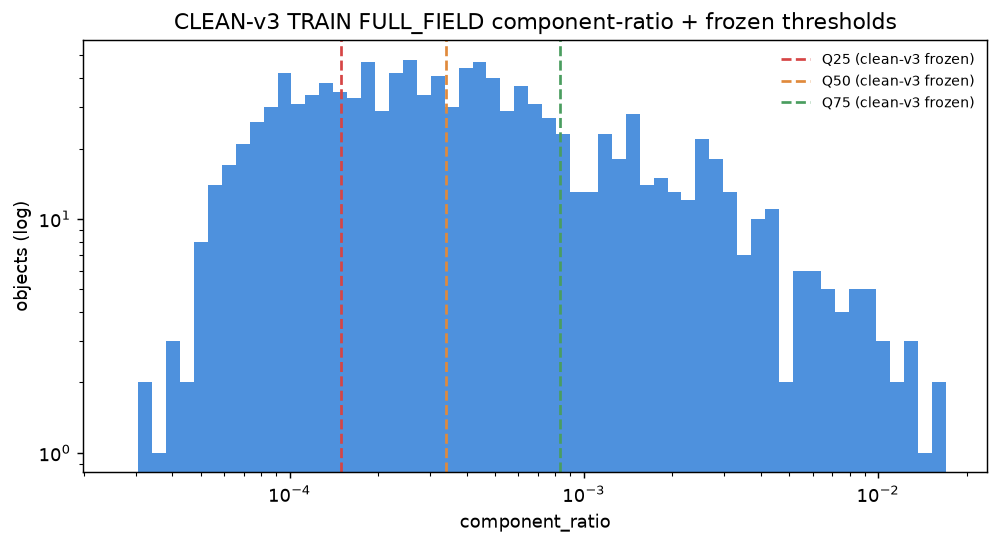

In [14]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[0])))

**Figure 2 — Historical vs clean-v3 threshold overlay**

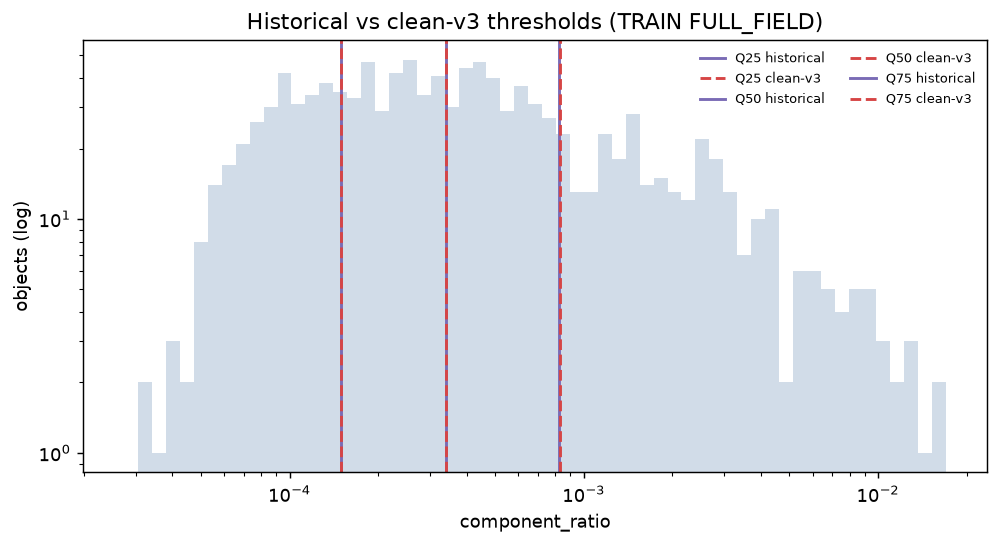

In [15]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[1])))

**Figure 3 — TRAIN historical vs clean stratum crosswalk**

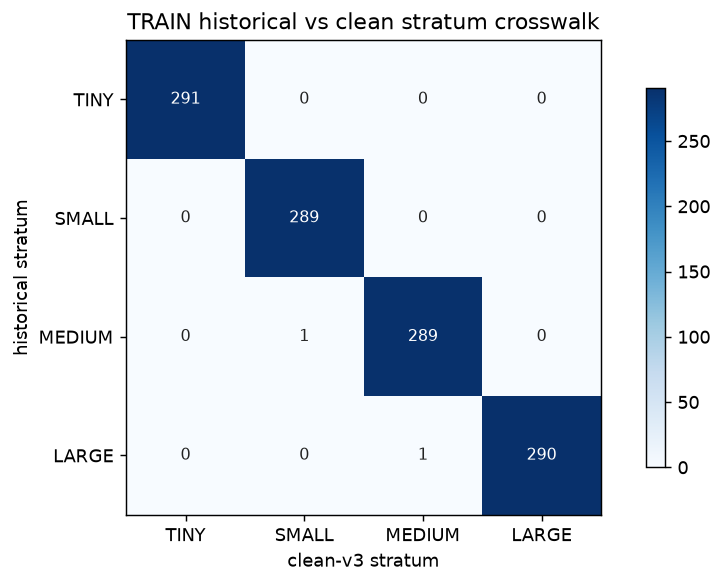

In [16]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[2])))

**Figure 4 — TRAIN frozen size distribution**

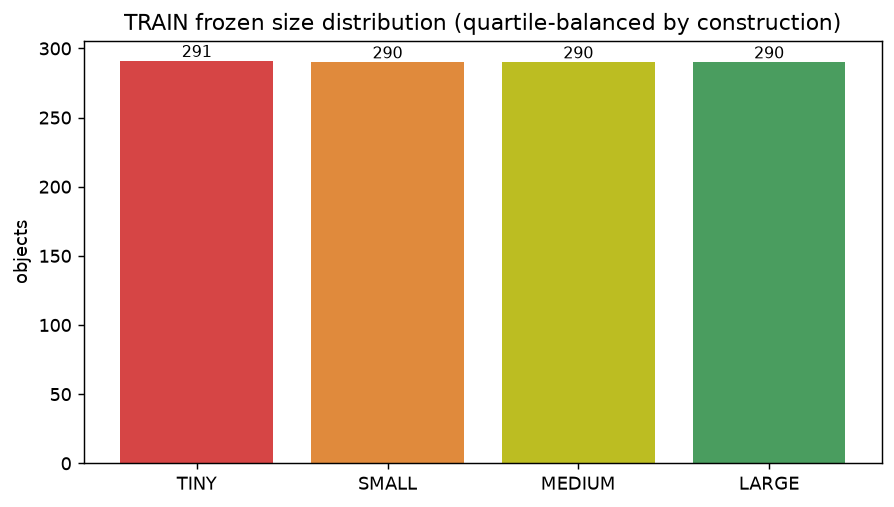

In [17]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[3])))

**Figure 5 — VAL frozen size distribution**

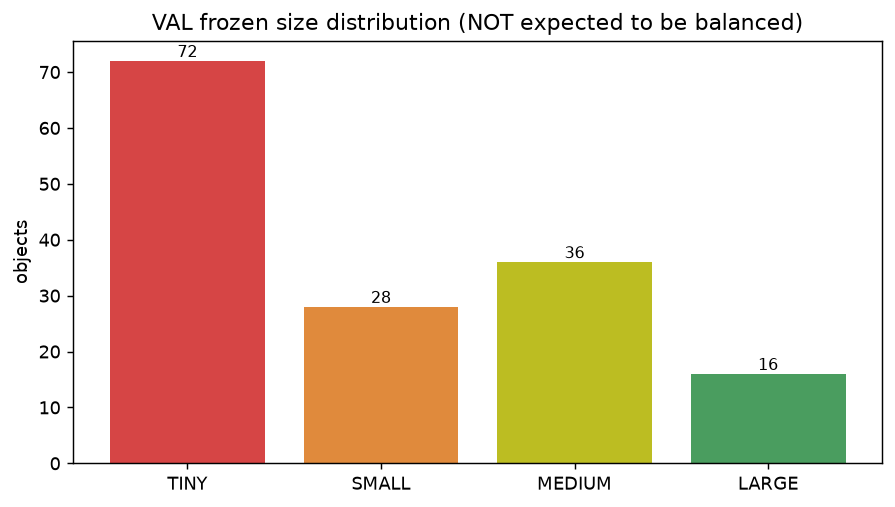

In [18]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[4])))

**Figure 6 — TRAIN vs VAL frozen size distribution comparison**

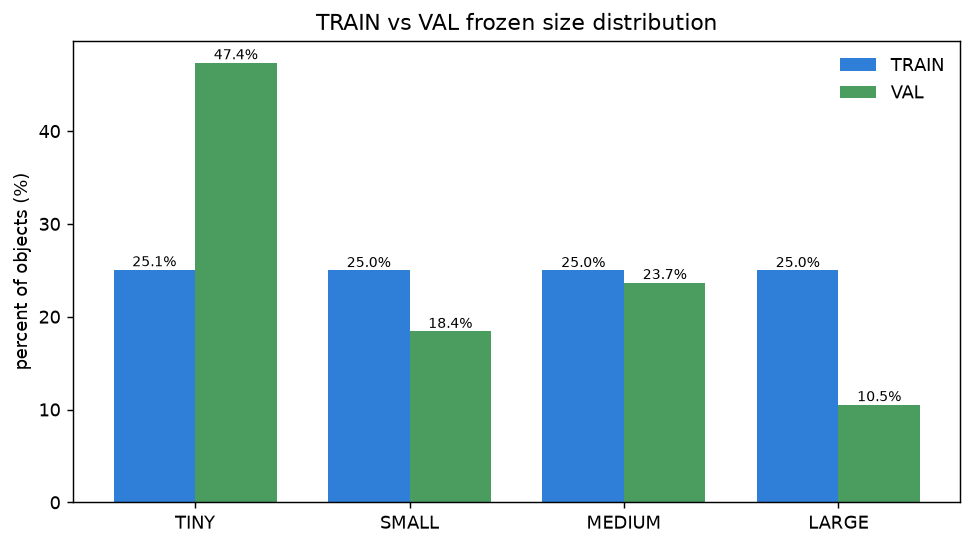

In [19]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[5])))

**Figure 7 — VAL category x frozen-size distribution**

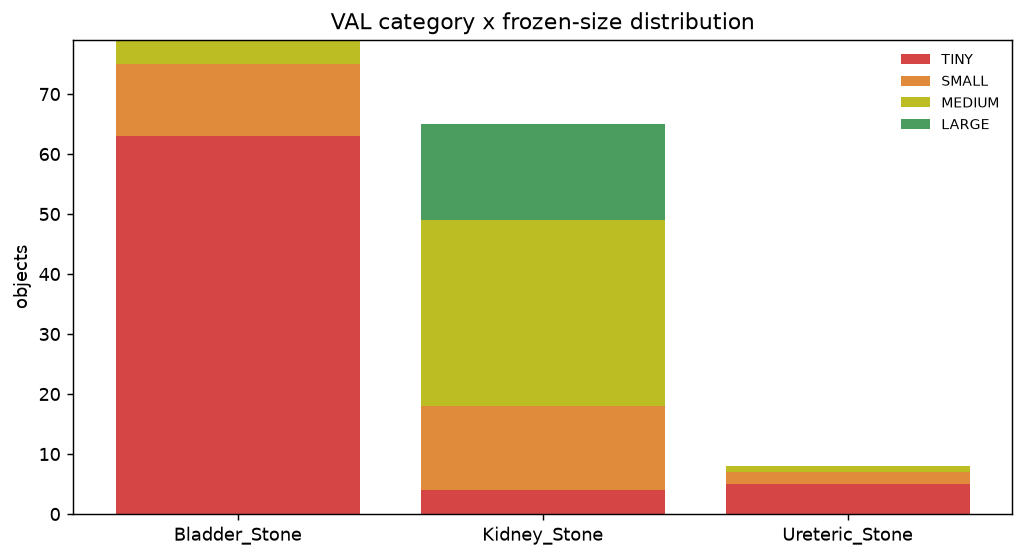

In [20]:
display(IPImage(filename=str(p7b.FIGDIR / p7b.FIGURE_NAMES[6])))

## 16. Multi-Component / Case-Level Semantics

The **primary taxonomy is object-level**. The case-level fields below are DERIVED
convenience metadata, not the taxonomy itself.

In [21]:
case_rows = []
for split, df in (('TRAIN', train_frozen), ('VAL', val_frozen)):
    for sid, sub in df.groupby('sample_id'):
        largest = sub.loc[sub['component_pixels'].idxmax()]
        present = set(sub['frozen_stratum'])
        case_rows.append({
            'split': split, 'sample_id': sid,
            'component_count': int(len(sub)),
            **{f'contains_{s.lower()}_object': (s in present) for s in p7b.STRATA},
            'dominant_object_stratum': largest['frozen_stratum'],
        })
case_df = pd.DataFrame(case_rows)
display(case_df.head(8))
print()
print('DERIVED case-level fields (NOT the primary taxonomy):')
print('  contains_{tiny,small,medium,large}_object')
print('  dominant_object_stratum = stratum of the largest component by component_pixels')
print()
print('cases with >1 component (TRAIN):',
      int((case_df[case_df.split=='TRAIN']['component_count'] >= 2).sum()))
print('cases with >1 component (VAL)  :',
      int((case_df[case_df.split=='VAL']['component_count'] >= 2).sum()))

,split,sample_id,component_count,contains_tiny_object,contains_small_object,contains_medium_object,contains_large_object,dominant_object_stratum
0,TRAIN,00898dbf7b16b032ac8299d37b8fe7d4,1,False,False,False,True,LARGE
1,TRAIN,0122c551577bfe20a57426e1e7e955c2,1,False,False,True,False,MEDIUM
2,TRAIN,01c5a11cce0ccb29d62f7916b839563e,1,False,False,False,True,LARGE
3,TRAIN,01e2d7043ae755a38411bdf1ad9339ca,1,True,False,False,False,TINY
4,TRAIN,02651cd047a891dcf6faafedee568c79,3,False,True,True,False,MEDIUM
5,TRAIN,029428961ddb4f21fd784454777a1524,1,False,True,False,False,SMALL
6,TRAIN,039cb89fd7c61d1e81e4d5050bea53af,1,True,False,False,False,TINY
7,TRAIN,03e510c377a3bb84320ea829ec1ae247,1,False,False,True,False,MEDIUM



DERIVED case-level fields (NOT the primary taxonomy):
  contains_{tiny,small,medium,large}_object
  dominant_object_stratum = stratum of the largest component by component_pixels

cases with >1 component (TRAIN): 206
cases with >1 component (VAL)  : 49


## 17. `ROI_NOT_PRIMARY_BINNED` Governance

ROI components are **not** primary-binned. No ROI-specific taxonomy is calibrated in
this task, and C2-style FULL_FIELD thresholds are **not** applied to ROI.

In [22]:
print('primary taxonomy acquisition scope : FULL_FIELD')
print('ROI handling                       : ROI_NOT_PRIMARY_BINNED')
print('ROI-specific taxonomy created      : NO')
print()
print('If an ROI-specific taxonomy becomes scientifically necessary it requires')
print('separate supervisor authorization.')

primary taxonomy acquisition scope : FULL_FIELD
ROI handling                       : ROI_NOT_PRIMARY_BINNED
ROI-specific taxonomy created      : NO

If an ROI-specific taxonomy becomes scientifically necessary it requires
separate supervisor authorization.


## 18. Correction — Part-1A C2 Cross-Regime Wording

The Part-1A recommendation JSON contained stale wording describing C2 as "the only
candidate meaningfully comparable across both regimes". That contradicted Part-1A's own
evidence: a FULL_FIELD-calibrated C2 rule sends ~99.5% of ROI components to LARGE.

**Correction (recorded here; the accepted Part-1A notebook is NOT modified):**

> C2 is **scale-normalized** but **NOT cross-regime calibrated**. This is one reason it
> was not selected.

In [23]:
print('CORRECTION RECORDED')
print('  C2 is scale-normalized but NOT cross-regime calibrated.')
print('  Evidence: a FULL_FIELD-calibrated C2 rule sends ~99.5% of ROI components to LARGE.')
print('  This is one reason C2 was not selected.')
print()
print('The accepted Part-1A notebook was NOT modified.')

CORRECTION RECORDED
  C2 is scale-normalized but NOT cross-regime calibrated.
  Evidence: a FULL_FIELD-calibrated C2 rule sends ~99.5% of ROI components to LARGE.
  This is one reason C2 was not selected.

The accepted Part-1A notebook was NOT modified.


## 19. Limitations

- "Tiny" is a **relative, TRAIN-derived geometric stratum**, not an absolute clinical definition.
- The taxonomy applies primarily to **FULL_FIELD** acquisition.
- **ROI is deliberately not primary-binned.**
- The thresholds depend on the clean-v3 TRAIN distribution.
- TRAIN is **quartile-balanced by construction**.
- VAL prevalence may differ because VAL composition differs.
- VAL was inspected **only after** the threshold freeze.
- **No TEST content was accessed.**
- No external literature was consulted.

## 20. Downstream Governance

- All CLEAN-v3 KUB work must use `taxonomy_id = kub_size_clean_v3_v1`.
- Historical v2 reports retain `kub_size_v1`.
- **Do not** compare historical and clean size labels as if the thresholds were numerically
  identical.
- Any result table containing size strata must record both `manifest_version` and `taxonomy_id`.

## 21. Artifact Hashes

In [24]:
ledger = {
    'taxonomy_id': p7b.CLEAN_TAXONOMY_ID,
    'status': 'FROZEN',
    'thresholds': CLEAN,
    'threshold_artifact': str(artifact_path.relative_to(PROJECT_ROOT)).replace('\\','/'),
    'threshold_artifact_sha': ARTIFACT_SHA,
    'manifest_version': 'phase4_v3',
    'derivation_objects': int(len(train_ff)),
    'object_table_sha': OBJECT_TABLE_SHA,
    'historical_reproduction_exact': repro['reproduced'],
    'val_reads_before_freeze': 0,
    'test_reads': 0,
}
print(json.dumps(ledger, indent=2))
print()
reg = p7b.final_table_registry(TABLES)
display(reg)
print('TABLE COUNT:', int(reg['exists'].sum()))

{
  "taxonomy_id": "kub_size_clean_v3_v1",
  "status": "FROZEN",
  "thresholds": {
    "Q25": 0.0001497998649691358,
    "Q50": 0.0003401438395182292,
    "Q75": 0.0008279682677469136
  },
  "threshold_artifact": "reports/audits/kub_size_clean_v3_v1_thresholds.json",
  "threshold_artifact_sha": "89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6",
  "manifest_version": "phase4_v3",
  "derivation_objects": 1161,
  "object_table_sha": "5c270dd4cb09e5697fdd5d7eb2ae4465f82489bb71ccead019a558934f5d1a08",
  "historical_reproduction_exact": true,
  "val_reads_before_freeze": 0,
  "test_reads": 0
}



,table,exists,bytes,sha256
0,phase07_clean_v3_threshold_derivation_objects.csv,True,112246,5c270dd4cb09e5697fdd5d7eb2ae4465f82489bb71ccea...
1,phase07_historical_vs_clean_thresholds.csv,True,375,6ddadd8f4717db0c6bc462247345d18ecb58a5ada71ffa...
2,phase07_train_historical_clean_label_crosswalk...,True,126217,d1cc3951c791003d6dc28f4bc7e41f93c8741cf3197727...
3,phase07_kub_v3_val_object_size_frozen.csv,True,17937,3300a266505eb4d21f91c685dea09edddb7f8b4cb51c3a...
4,phase07_kub_v3_frozen_taxonomy_summary.csv,True,1819,74705df82683da4ae204e51d326e0e2b614174ab5c1f49...


TABLE COUNT: 5


## 22. Conclusion

The clean-v3 tiny-object taxonomy `kub_size_clean_v3_v1` is **FROZEN**. It preserves the
historical scientific design (object-level, 8-connectivity, `mask > 0`, FULL_FIELD,
normalized component area) with numerical quartiles re-derived from CLEAN-v3 TRAIN.
The historical quantile method was reproduced exactly. VAL was characterized only after
the freeze and its thresholds were not adjusted. TEST remained locked.

In [25]:
print('=' * 62)
print('PHASE 07 PART 1B — FINAL STATUS')
print('=' * 62)
print('TAXONOMY        :', p7b.CLEAN_TAXONOMY_ID)
print('STATUS          : FROZEN')
print('Q25/Q50/Q75     :', repr(CLEAN['Q25']), repr(CLEAN['Q50']), repr(CLEAN['Q75']))
print('ARTIFACT SHA    :', ARTIFACT_SHA)
print('VAL reads before freeze : 0')
print('TEST reads              : 0')
print('THRESHOLDS CHANGED AFTER VAL : NO')
print('PHASE 08 STARTED        : NO')
print('=' * 62)

PHASE 07 PART 1B — FINAL STATUS
TAXONOMY        : kub_size_clean_v3_v1
STATUS          : FROZEN
Q25/Q50/Q75     : 0.0001497998649691358 0.0003401438395182292 0.0008279682677469136
ARTIFACT SHA    : 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
VAL reads before freeze : 0
TEST reads              : 0
THRESHOLDS CHANGED AFTER VAL : NO
PHASE 08 STARTED        : NO
